# GENERAL_LINEAR_MODELS

Baseline benchmarking with general linear models (Section 3.3) and the assumption tests in Tab 2. Runs on every lead 0 target, including the derivative targets, which are only modeled here.

Models: Dummy Regressor (mean), linear regression, degree 2 polynomial on all features, and degree 2 polynomial best subset (every combination of 1 to 3 original features).

Splits are the original 70/15/15 by row index. Models are fit on the training rows ONLY. The best feature subset is picked on the validation rows ONLY. Test metrics are saved to a separate file FOR REPORTING ONLY and are NOT USED TO PICK ANYTHING.

In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


## Imports

In [2]:
import itertools
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.api as sms
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
import warnings

## Configuration

In [3]:
MANIFEST_PATH = Path("data/processed/manifest.json")
RESULTS_DIR = Path("results/glm")
IMAGES_PATH = Path("images/glm")
LOCKED_SELECTION_PATH = Path("results/simulation/locked_selection.json")
TEST_PREDICTION_DIR = Path("results/predictions/test")

SAMPLINGS = None # None = all sampling rates
TARGETS = None # None = all lead 0 targets (drift + derivative)
POLY_DEGREE = 2
POLY_MAX_SUBSET_SIZE = 3

# Assumption tests: same configuration as the original GLM notebook
DIAGNOSTIC_SAMPLING = "30SEC"
DIAGNOSTIC_TARGET = "RSTDEV_FWD_300_SAVGOL"
VIF_THRESHOLD = 5.0
LJUNG_BOX_LAG = 10
ALPHA = 0.05

# Residual autocorrelation of the locked test model
RESIDUAL_ACF_MAX_LAG_MIN = 60
LJUNG_BOX_LAGS_MIN = [5, 10, 30, 60]

mpl.rc("axes", labelsize=14)
mpl.rc("xtick", labelsize=12)
mpl.rc("ytick", labelsize=12)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

manifest = json.loads(MANIFEST_PATH.read_text())
FEATURES = manifest["feature_columns"]
TARGET_META = {t["name"]: t for t in manifest["targets"]}
SAMPLING_S = manifest["sampling_s"]
SAMPLINGS = SAMPLINGS or list(SAMPLING_S)
TARGETS = TARGETS or [t["name"] for t in manifest["targets"] if t["primary"]]
TZ = manifest["display_timezone"]

## Splits and metrics

In [4]:
def load_dataset(sampling):
    df = pd.read_csv(manifest["files"]["datasets"][sampling])
    assert len(df) == manifest["splits"][sampling]["n"], "dataset does not match manifest - rerun DATA_PROCESSING"
    return df


def split_masks(df, sampling, target):
    """70/15/15 by row. Rows whose label window runs into the next split are dropped."""
    sp = manifest["splits"][sampling]
    idx = np.arange(len(df))
    end = df["current_time"].to_numpy() + TARGET_META[target]["window_end_offset_s"] * 1000
    has = df[target].notna().to_numpy()
    train = (idx < sp["n_train"]) & (end <= sp["validation_start_ms"]) & has
    val = (idx >= sp["n_train"]) & (idx < sp["n_train"] + sp["n_validation"]) & (end <= sp["test_start_ms"]) & has
    test = (idx >= sp["n_train"] + sp["n_validation"]) & has
    return train, val, test


def metrics(y, yhat):
    return {"rmse": float(np.sqrt(mean_squared_error(y, yhat))), "r2": float(r2_score(y, yhat))}


def save_fig(fig_id, tight_layout=True, resolution=300):
    if tight_layout:
        plt.tight_layout()
    plt.savefig(IMAGES_PATH / f"{fig_id}.png", dpi=resolution)

## Models

Scaling: StandardScaler (fit on training rows) before OLS keeps coefficients and poly terms on comparable scales and the design matrix well conditioned. The dummy model needs no scaling.

In [5]:
def linear_pipeline():
    return Pipeline([("scale", StandardScaler()), ("ols", LinearRegression())])


def poly_pipeline(feature_idx=None):
    steps = [] if feature_idx is None else [("select", ColumnTransformer([("keep", "passthrough", list(feature_idx))], remainder="drop"))]
    steps += [("poly", PolynomialFeatures(degree=POLY_DEGREE, include_bias=False)), ("scale", StandardScaler()), ("ols", LinearRegression())]
    
    return Pipeline(steps)


SUBSETS = [c for k in range(1, POLY_MAX_SUBSET_SIZE + 1) for c in itertools.combinations(range(len(FEATURES)), k)]


def best_poly_subset(X, y, train, val):
    # Selection criterion is val R^2 for every model in the study (comparable across targets, negative values are kept). RMSE is reported alongside.
    best, best_r2 = None, -np.inf
    
    for combo in SUBSETS:
        r2 = r2_score(y[val], poly_pipeline(combo).fit(X[train], y[train]).predict(X[val]))
        
        if r2 > best_r2:
            best, best_r2 = combo, r2
            
    return best

## Fit and evaluate

In [6]:
datasets = {s: load_dataset(s) for s in SAMPLINGS}
val_rows, test_rows = [], []

for sampling in SAMPLINGS:
    
    df = datasets[sampling]
    X = df[FEATURES].to_numpy(float)
    
    for target in TARGETS:
        
        y = df[target].to_numpy(float)
        train, val, test = split_masks(df, sampling, target)
        combo = best_poly_subset(X, y, train, val)
        models = {
            "dummy_baseline": (DummyRegressor(strategy="mean"), ""),
            "linear": (linear_pipeline(), ""),
            "poly_all_features": (poly_pipeline(), ""),
            "poly_best_subset": (poly_pipeline(combo), ", ".join(FEATURES[i] for i in combo)),
        }
        
        for name, (est, features_used) in models.items():
            est.fit(X[train], y[train])
            m_tr, m_va, m_te = (metrics(y[m], est.predict(X[m])) for m in (train, val, test))
            key = {"sampling frequency": sampling, "model_name": name, "target_name": target, "features": features_used}
            val_rows.append({**key, "n_train": int(train.sum()), "n_validation": int(val.sum()), "training_rmse": m_tr["rmse"], "training_r2": m_tr["r2"], "validation_rmse": m_va["rmse"], "validation_r2": m_va["r2"]})
            test_rows.append({**key, "n_test": int(test.sum()), "test_rmse": m_te["rmse"], "test_r2": m_te["r2"]})
            
        print(f"{sampling:6s} {target:28s} best subset: {models['poly_best_subset'][1]}")

glm_results = pd.DataFrame(val_rows)
glm_results.to_csv(RESULTS_DIR / "glm_validation_results.csv", index=False)
pd.DataFrame(test_rows).to_csv(RESULTS_DIR / "glm_test_results.csv", index=False) # reporting only
glm_results.sort_values(["sampling frequency", "target_name", "validation_r2"], ascending=[True, True, False])

30SEC  REXD_FWD_300                 best subset: cloud_cover_y, wind_u_y, wind_v_y
30SEC  REXD_FWD_300_DSAVG           best subset: cloud_cover_y, wind_u_y, wind_v_y
30SEC  REXD_FWD_300_DSMAX           best subset: cloud_cover_y, wind_u_y, wind_v_y
30SEC  REXD_FWD_300_SAVGOL          best subset: wind_u_x, cloud_cover_y, wind_speed_y
30SEC  REXD_FWD_600                 best subset: wind_u_x, cloud_cover_y, wind_u_y
30SEC  REXD_FWD_600_DSAVG           best subset: wind_u_x, cloud_cover_y, wind_u_y
30SEC  REXD_FWD_600_DSMAX           best subset: wind_u_x, cloud_cover_y, wind_u_y
30SEC  REXD_FWD_600_SAVGOL          best subset: tod_sin, wind_speed_x, wind_speed_y
30SEC  REXD_FWD_1200                best subset: tod_sin, wind_speed_x, wind_u_y
30SEC  REXD_FWD_1200_DSAVG          best subset: tod_sin, wind_speed_x, wind_u_y
30SEC  REXD_FWD_1200_DSMAX          best subset: tod_sin, wind_speed_x, wind_u_y
30SEC  REXD_FWD_1200_SAVGOL         best subset: tod_sin, wind_speed_x, wind_speed_y
30

,sampling frequency,model_name,target_name,features,n_train,n_validation,training_rmse,training_r2,validation_rmse,validation_r2
163,1MIN,poly_best_subset,REXD_FWD_1200,"tod_sin, wind_speed_x, wind_u_y",2882,616,0.099350,0.436996,0.069926,0.584711
161,1MIN,linear,REXD_FWD_1200,,2882,616,0.096587,0.467879,0.089102,0.325708
160,1MIN,dummy_baseline,REXD_FWD_1200,,2882,616,0.132407,0.000000,0.109797,-0.023884
162,1MIN,poly_all_features,REXD_FWD_1200,,2882,616,0.071241,0.710511,0.709419,-41.744080
167,1MIN,poly_best_subset,REXD_FWD_1200_DSAVG,"tod_sin, wind_speed_x, wind_u_y",2880,614,0.095944,0.454031,0.067664,0.602941
...,...,...,...,...,...,...,...,...,...,...
106,30SEC,poly_all_features,d_Fidelity_FWD_DSMAX,,5758,1228,0.030072,0.406097,0.221935,-55.282807
111,30SEC,poly_best_subset,d_Fidelity_FWD_SAVGOL,"tod_sin, wind_speed_x, wind_speed_y",5658,1228,0.053467,0.366798,0.031521,0.580761
109,30SEC,linear,d_Fidelity_FWD_SAVGOL,,5658,1228,0.051220,0.418891,0.046192,0.099689
108,30SEC,dummy_baseline,d_Fidelity_FWD_SAVGOL,,5658,1228,0.067191,0.000000,0.049334,-0.026943


In [7]:
best_per_target = (glm_results[glm_results["model_name"] != "dummy_baseline"].sort_values("validation_r2", ascending=False).groupby(["sampling frequency", "target_name"]).head(1))
best_per_target.sort_values("validation_r2", ascending=False).head(20)

,sampling frequency,model_name,target_name,features,n_train,n_validation,training_rmse,training_r2,validation_rmse,validation_r2
319,2MIN,poly_best_subset,RSTDEV_FWD_300_SAVGOL,"wind_u_x, wind_gust_y, wind_speed_y",1417,308,0.018367,0.500178,0.012042,0.733570
191,1MIN,poly_best_subset,RSTDEV_FWD_300_SAVGOL,"wind_u_x, wind_gust_y, wind_speed_y",2831,615,0.018665,0.491140,0.012645,0.716829
335,2MIN,poly_best_subset,RSTDEV_FWD_600_SAVGOL,"tod_sin, wind_speed_x, wind_speed_y",1417,308,0.027318,0.481165,0.014214,0.716806
315,2MIN,poly_best_subset,RSTDEV_FWD_300_DSMAX,"wind_u_x, wind_gust_y, wind_speed_y",1441,308,0.017561,0.448169,0.011293,0.699916
63,30SEC,poly_best_subset,RSTDEV_FWD_300_SAVGOL,"wind_u_x, wind_gust_y, wind_speed_y",5661,1231,0.019112,0.480839,0.013272,0.697953
311,2MIN,poly_best_subset,RSTDEV_FWD_300_DSAVG,"wind_u_x, cloud_cover_y, wind_u_y",1441,308,0.009673,0.448117,0.007048,0.697788
287,2MIN,poly_best_subset,REXD_FWD_600_SAVGOL,"wind_u_x, wind_gust_y, wind_speed_y",1417,308,0.104989,0.438316,0.065552,0.689709
207,1MIN,poly_best_subset,RSTDEV_FWD_600_SAVGOL,"tod_sin, wind_speed_x, wind_speed_y",2831,615,0.028355,0.463132,0.015278,0.689375
283,2MIN,poly_best_subset,REXD_FWD_600_DSMAX,"tod_sin, wind_speed_x, wind_u_y",1441,308,0.088655,0.492686,0.058484,0.680788
271,2MIN,poly_best_subset,REXD_FWD_300_SAVGOL,"temperature_y, wind_speed_y",1417,308,0.071900,0.484402,0.055013,0.680523


## Actual vs predicted (diagnostic configuration)

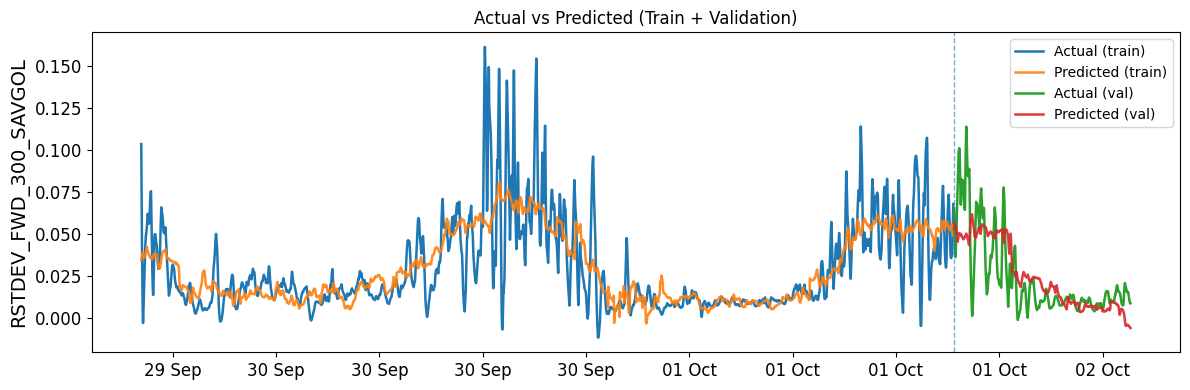

In [8]:
df_d = datasets[DIAGNOSTIC_SAMPLING]
X_d = df_d[FEATURES].to_numpy(float)
y_d = df_d[DIAGNOSTIC_TARGET].to_numpy(float)
tr_d, va_d, _ = split_masks(df_d, DIAGNOSTIC_SAMPLING, DIAGNOSTIC_TARGET)
lin_d = linear_pipeline().fit(X_d[tr_d], y_d[tr_d])
dt_d = pd.to_datetime(df_d["current_time"], unit="ms", utc=True).dt.tz_convert(TZ)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(dt_d[tr_d], y_d[tr_d], label="Actual (train)", linewidth=1.8)
ax.plot(dt_d[tr_d], lin_d.predict(X_d[tr_d]), label="Predicted (train)", linewidth=1.8, alpha=0.9)
ax.plot(dt_d[va_d], y_d[va_d], label="Actual (val)", linewidth=1.8)
ax.plot(dt_d[va_d], lin_d.predict(X_d[va_d]), label="Predicted (val)", linewidth=1.8, alpha=0.9)
ax.axvline(dt_d[va_d].iloc[0], linestyle="--", linewidth=1, alpha=0.6)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=TZ))
ax.set_ylabel(DIAGNOSTIC_TARGET)
ax.set_title("Actual vs Predicted (Train + Validation)")
ax.legend()
save_fig(f"linear_train_val_{DIAGNOSTIC_SAMPLING}_{DIAGNOSTIC_TARGET}")
plt.show()

## Assumption tests (Table 2), taken from Dr. S-K's course

| Assumption | Test | Remedial measure |
|---|---|---|
| No multicollinearity | VIF | Remove high VIF features, re-test |
| Residual normality | Jarque Bera, DAgostino K^2 | Standardize features |
| Residual autocorrelation | Durbin Watson, Ljung Box | Cochrane Orcutt |
| Heteroscedasticity | Breusch Pagan | Transform Y |
| Linearity | RESET F test | Transform X (polynomial terms) |

Training rows are used for VIF, RESET and Cochrane Orcutt test, resid tests use val resids of the training fit, just like in my previous notebook.

### Multicollinearity

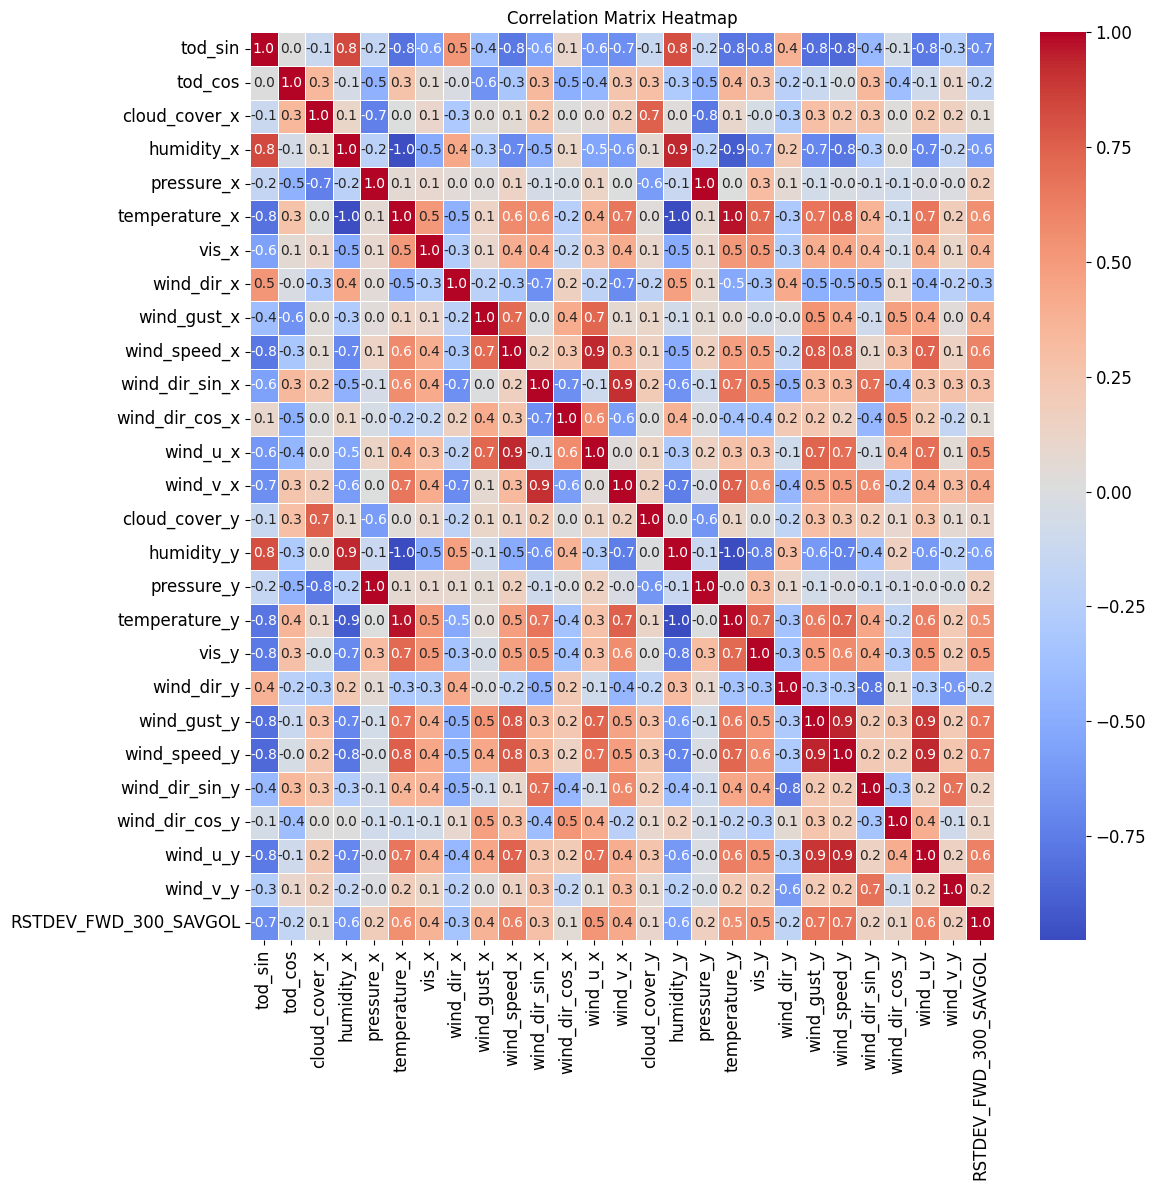

wind_u_x          380.613034
wind_speed_x      307.052177
temperature_x     200.162180
pressure_y        195.926237
pressure_x        179.101402
temperature_y     120.530062
humidity_x        114.071406
humidity_y        105.403659
wind_dir_cos_x     45.259632
wind_speed_y       37.003843
wind_dir_sin_x     35.759158
wind_v_x           34.857770
tod_sin            20.332477
wind_u_y           19.404453
wind_gust_y        16.707809
wind_dir_sin_y     10.741413
tod_cos             9.799970
vis_y               9.183109
wind_gust_x         7.101052
cloud_cover_x       5.931878
wind_dir_cos_y      5.081371
wind_v_y            4.214025
wind_dir_x          3.800139
cloud_cover_y       3.549936
wind_dir_y          3.139590
vis_x               1.759094


In [9]:
X_train_df = df_d.loc[tr_d, FEATURES]
plt.figure(figsize=(12, 12))
sns.heatmap(pd.concat([X_train_df, df_d.loc[tr_d, [DIAGNOSTIC_TARGET]]], axis=1).corr(), annot=True, cmap="coolwarm", fmt=".1f", linewidths=.5)
plt.title("Correlation Matrix Heatmap")
save_fig(f"CORRMATX_{DIAGNOSTIC_TARGET}")
plt.show()


def vif_table(X_df):
    Xc = sm.add_constant(X_df, has_constant="add")
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=Xc.columns[1:], name="VIF").sort_values(ascending=False)


print(vif_table(X_train_df).to_string())

In [10]:
X_vif, dropped = X_train_df.copy(), []

while X_vif.shape[1] > 1:
    vifs = vif_table(X_vif)
    if vifs.iloc[0] <= VIF_THRESHOLD:
        break
    dropped.append((vifs.index[0], float(vifs.iloc[0])))
    X_vif = X_vif.drop(columns=[vifs.index[0]])
    
print("Dropped (in order):")

for f, v in dropped:
    print(f"  {f:>30}  VIF={v:.3f}")
    
print("\nRemaining:", list(X_vif.columns))
print("\nFinal VIFs:\n", vif_table(X_vif).to_string())

Dropped (in order):
                        wind_u_x  VIF=380.613
                   temperature_x  VIF=199.439
                      pressure_y  VIF=193.265
                      humidity_y  VIF=100.061
                    wind_speed_y  VIF=33.763
                      humidity_x  VIF=30.814
                  wind_dir_sin_x  VIF=21.933
                         tod_sin  VIF=12.657
                     wind_gust_y  VIF=10.168
                         tod_cos  VIF=6.358
                    wind_speed_x  VIF=6.136
                        wind_v_x  VIF=5.966
                  wind_dir_sin_y  VIF=5.460
                        wind_u_y  VIF=5.285

Remaining: ['cloud_cover_x', 'pressure_x', 'vis_x', 'wind_dir_x', 'wind_gust_x', 'wind_dir_cos_x', 'cloud_cover_y', 'temperature_y', 'vis_y', 'wind_dir_y', 'wind_dir_cos_y', 'wind_v_y']

Final VIFs:
 cloud_cover_x     4.126840
pressure_x        3.342228
vis_y             3.230018
temperature_y     3.180655
cloud_cover_y     2.451511
wind_dir_y     

### Linearity (RESET)

In [11]:
def reset_test(y, Xc):
    base = sm.OLS(y, Xc).fit()
    yhat = np.asarray(base.fittedvalues)
    aug = sm.OLS(y, np.column_stack([Xc, yhat ** 2, yhat ** 3])).fit()
    F, p, _ = aug.compare_f_test(base)
    return float(F), float(p)


reset_rows = []
for target in TARGETS:
    train, _, _ = split_masks(df_d, DIAGNOSTIC_SAMPLING, target)
    y = df_d.loc[train, target].to_numpy(float)
    F_lin, p_lin = reset_test(y, sm.add_constant(df_d.loc[train, FEATURES].astype(float), has_constant="add"))
    Xp = PolynomialFeatures(degree=POLY_DEGREE, include_bias=False).fit_transform(df_d.loc[train, FEATURES])
    # F_poly, p_poly = reset_test(y, sm.add_constant(Xp[:, Xp.std(axis=0) > 0], has_constant="add"))
    # degree 2 terms are exactly dependent by construction (sin^2 + cos^2 = 1, u^2 + v^2 = speed^2, speed * sin(dir) = -u), so thiis design is always rank deficient, the F test uses the actual rank
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", SingularMatrixWarning)
        F_poly, p_poly = reset_test(y, sm.add_constant(Xp[:, Xp.std(axis=0) > 0], has_constant="add"))
    reset_rows.append({"target": target, "RESET_linear_F": F_lin, "RESET_linear_p": p_lin, "RESET_poly_F": F_poly, "RESET_poly_p": p_poly})
    
reset_results = pd.DataFrame(reset_rows)
reset_results

,target,RESET_linear_F,RESET_linear_p,RESET_poly_F,RESET_poly_p
0,REXD_FWD_300,76.791670,1.225941e-33,122.111887,1.362935e-52
1,REXD_FWD_300_DSAVG,93.330741,1.297066e-40,149.092635,9.542852e-64
2,REXD_FWD_300_DSMAX,102.910105,1.231430e-44,192.769808,1.390924e-81
3,REXD_FWD_300_SAVGOL,61.606155,3.413906e-27,515.261596,3.725856e-205
4,REXD_FWD_600,85.361160,2.945741e-37,220.766505,7.077295e-93
5,REXD_FWD_600_DSAVG,97.620358,2.042612e-42,245.436395,9.829491e-103
6,REXD_FWD_600_DSMAX,96.736883,4.800525e-42,330.392422,4.574659e-136
7,REXD_FWD_600_SAVGOL,97.739097,1.873295e-42,801.924906,7.322965e-305
8,REXD_FWD_1200,97.157051,3.195545e-42,385.943705,2.313766e-157
9,REXD_FWD_1200_DSAVG,105.889226,6.958110e-46,392.945582,5.193652e-160


### Autocorrelation, normality, heteroscedasticity

In [12]:
def residual_tests(kind, target):
    
    train, val, _ = split_masks(df_d, DIAGNOSTIC_SAMPLING, target)
    X_tr, X_va = df_d.loc[train, FEATURES].to_numpy(float), df_d.loc[val, FEATURES].to_numpy(float)
    y_tr, y_va = df_d.loc[train, target].to_numpy(float), df_d.loc[val, target].to_numpy(float)
    est = (linear_pipeline() if kind == "linear" else poly_pipeline()).fit(X_tr, y_tr)
    r = y_va - est.predict(X_va)
    lb = sms.acorr_ljungbox(r, lags=[LJUNG_BOX_LAG], return_df=True)
    
    _, jb_p, _, _ = sm.stats.jarque_bera(r)
    _, k2_p = stats.normaltest(r, nan_policy="omit")
    # _, bp_p, _, bp_f_p = sms.het_breuschpagan(r, sm.add_constant(X_va, has_constant="add"))
    X_bp = X_va[:, X_va.std(axis=0) > 0] # constant features (e.g., vis_x at its 16 km cap) duplicate the intercept
    _, bp_p, _, bp_f_p = sms.het_breuschpagan(r, sm.add_constant(X_bp, has_constant="add"))
    
    row = {"model": kind, "target": target, "durbin_watson": float(sm.stats.stattools.durbin_watson(r)), "ljung_box_p": float(lb["lb_pvalue"].iloc[0]), "jarque_bera_p": float(jb_p), "dagostino_k2_p": float(k2_p), "breusch_pagan_lm_p": float(bp_p), "breusch_pagan_f_p": float(bp_f_p)}
    
    if kind == "linear":
        glsar = sm.GLSAR(y_tr, sm.add_constant(StandardScaler().fit_transform(X_tr), has_constant="add"), rho=1)
        res = glsar.iterative_fit(maxiter=20)
        row["cochrane_orcutt_rho"] = float(res.model.rho[0])
        row["cochrane_orcutt_dw"] = float(sm.stats.stattools.durbin_watson(res.wresid))
        
    return row, est, X_va, y_va


assumptions = pd.DataFrame([residual_tests(kind, t)[0] for kind in ("linear", "poly") for t in TARGETS])

for c in [c for c in assumptions.columns if c.endswith("_p")]:
    assumptions[c.replace("_p", "_reject")] = assumptions[c] < ALPHA
    
assumptions = assumptions.merge(reset_results, on="target", how="left")
assumptions.to_csv(RESULTS_DIR / f"assumption_tests_{DIAGNOSTIC_SAMPLING}.csv", index=False)
assumptions

,model,target,durbin_watson,ljung_box_p,jarque_bera_p,dagostino_k2_p,breusch_pagan_lm_p,breusch_pagan_f_p,cochrane_orcutt_rho,cochrane_orcutt_dw,ljung_box_reject,jarque_bera_reject,dagostino_k2_reject,breusch_rejectagan_lm_reject,breusch_rejectagan_f_reject,RESET_linear_F,RESET_linear_p,RESET_poly_F,RESET_poly_p
0,linear,REXD_FWD_300,0.368024,0.0,3.214424e-284,8.680073e-71,3.162896e-85,5.911078e-110,0.650873,2.203979,True,True,True,True,True,76.791670,1.225941e-33,122.111887,1.362935e-52
1,linear,REXD_FWD_300_DSAVG,0.163669,0.0,2.918518e-173,8.763076e-57,2.258903e-110,9.448839e-155,0.774253,1.929215,True,True,True,True,True,93.330741,1.297066e-40,149.092635,9.542852e-64
2,linear,REXD_FWD_300_DSMAX,0.167122,0.0,1.215937e-179,8.001105e-60,2.775099e-106,6.242948e-147,0.803897,1.828483,True,True,True,True,True,102.910105,1.231430e-44,192.769808,1.390924e-81
3,linear,REXD_FWD_300_SAVGOL,0.007616,0.0,4.768634e-12,3.875083e-07,8.053825e-154,5.700200e-257,0.995518,0.155336,True,True,True,True,True,61.606155,3.413906e-27,515.261596,3.725856e-205
4,linear,REXD_FWD_600,0.198371,0.0,4.436880e-128,1.483681e-50,2.039244e-95,3.941807e-127,0.765433,1.806490,True,True,True,True,True,85.361160,2.945741e-37,220.766505,7.077295e-93
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,poly,d_Fidelity_FWD_SAVGOL,0.003624,0.0,4.945677e-16,3.776467e-13,2.435329e-201,0.000000e+00,NaN,NaN,True,True,True,True,True,95.843475,1.171503e-41,1174.539484,0.000000e+00
60,poly,d2_Fidelity_FWD,0.013628,0.0,8.031143e-08,3.013074e-07,3.605185e-217,0.000000e+00,NaN,NaN,True,True,True,True,True,33.962241,2.173395e-15,162.355333,3.434604e-69
61,poly,d2_Fidelity_FWD_DSAVG,0.039956,0.0,2.951714e-31,1.484290e-18,1.713332e-157,3.929998e-269,NaN,NaN,True,True,True,True,True,50.199683,2.440702e-22,252.046601,2.342798e-105
62,poly,d2_Fidelity_FWD_DSMAX,0.026731,0.0,6.494277e-09,3.763064e-08,7.907402e-185,0.000000e+00,NaN,NaN,True,True,True,True,True,49.449361,5.102707e-22,310.743438,1.963340e-128


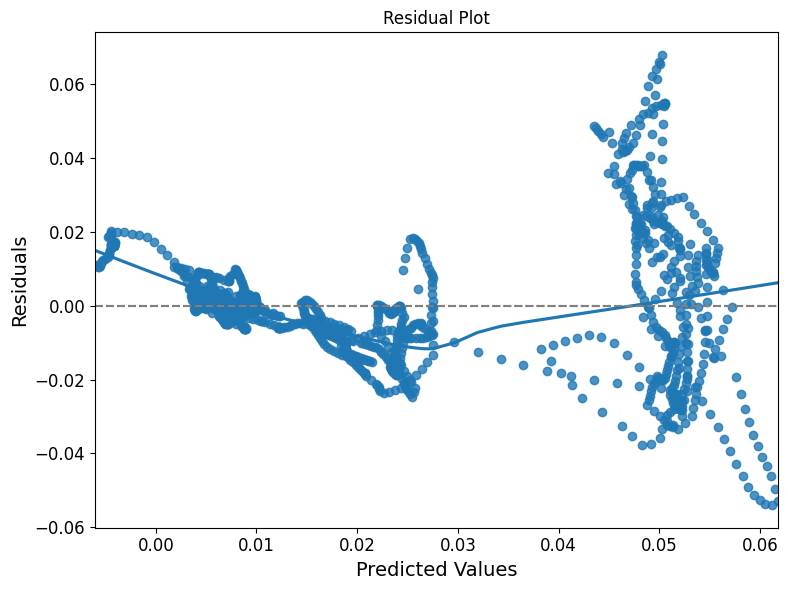

In [13]:
_, est_d, X_va_d, y_va_d = residual_tests("linear", DIAGNOSTIC_TARGET)
yhat_va_d = est_d.predict(X_va_d)

plt.figure(figsize=(8, 6))
sns.residplot(x=yhat_va_d, y=y_va_d - yhat_va_d, lowess=True)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.axhline(y=0, color="gray", linestyle="--")
save_fig(f"residplot_{DIAGNOSTIC_SAMPLING}_{DIAGNOSTIC_TARGET}")


plt.show()

## Residual autocorrelation of the locked test model (reviewer request)

Uses the model locked in STATIC_SIMULATION notebook and its saved test predictions. Rerun this section after those exist (just run this last). Overlapping label windows on consecutive rows add some autocorrelation on their own.

TODO: Make this separate notebook so I can run it after everything else?

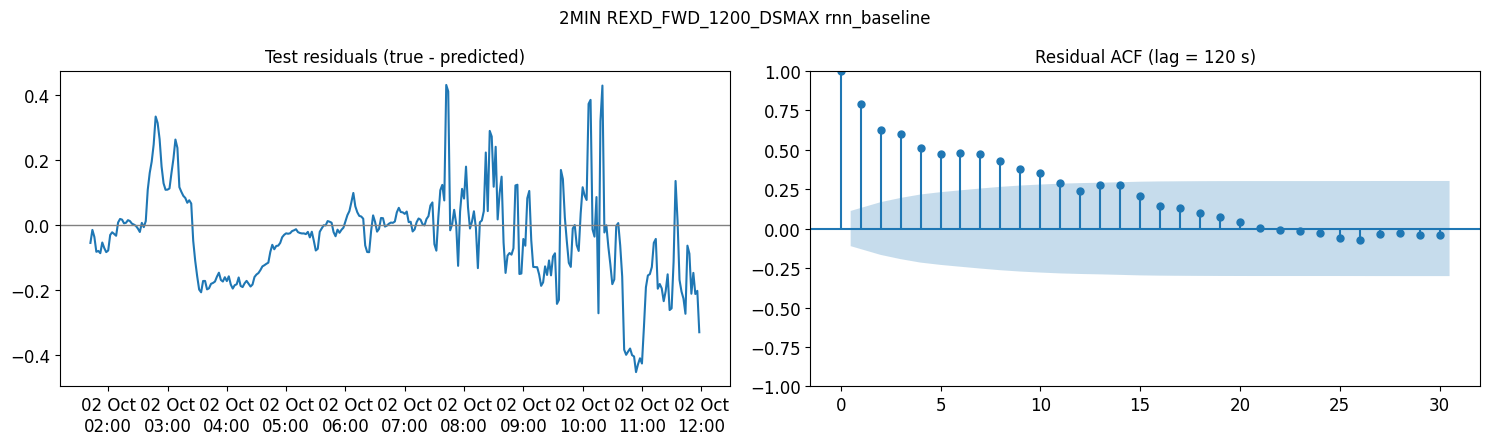

,lb_stat,lb_pvalue
lag 2 (4.0 min),315.154887,3.672702e-69
lag 5 (10.0 min),581.591036,1.919088e-123
lag 15 (30.0 min),974.421399,4.082527e-198
lag 30 (60.0 min),997.133716,2.066465e-190


In [5]:
def residual_autocorrelation_report(pred, label):
    
    pred = pred.sort_values("current_time")
    step_s = SAMPLING_S[pred["sampling"].iloc[0]]
    resid = (pred["y_true"] - pred["y_pred"]).to_numpy()
    lags = [l for l in sorted({max(1, round(m * 60 / step_s)) for m in LJUNG_BOX_LAGS_MIN}) if l < len(resid)]
    lb = sms.acorr_ljungbox(resid, lags=lags, return_df=True)
    lb.index = [f"lag {l} ({l * step_s / 60:.1f} min)" for l in lags]
    dt = pd.to_datetime(pred["current_time"], unit="ms", utc=True).dt.tz_convert(TZ)
    
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 4.5))
    ax0.plot(dt, resid)
    ax0.axhline(0, color="gray", linewidth=1)
    ax0.set_title("Test residuals (true - predicted)")
    ax0.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M", tz=TZ))
    plot_acf(resid, lags=max(1, int(RESIDUAL_ACF_MAX_LAG_MIN * 60 / step_s)), ax=ax1)
    ax1.set_title(f"Residual ACF (lag = {step_s} s)")
    fig.suptitle(label)
    save_fig(f"test_residual_acf_{label.replace(' ', '_')}")
    plt.show()
    
    return lb


if not LOCKED_SELECTION_PATH.exists():
    print("No locked selection yet, run STATIC_SIMULATION first.")
    
else:
    lock = json.loads(LOCKED_SELECTION_PATH.read_text())
    test_file = TEST_PREDICTION_DIR / f"{lock['sampling']}__{lock['target']}__{lock['model']}.csv"
    
    if not test_file.exists():
        print(f"Missing {test_file}") # probs not necessary, but included anyway
    else:
        lb_table = residual_autocorrelation_report(pd.read_csv(test_file), f"{lock['sampling']} {lock['target']} {lock['model']}")
        lb_table.to_csv(RESULTS_DIR / "locked_model_test_ljung_box.csv")
        display(lb_table)